# Web Scraping and Macroeconomic Analysis of Five European Nations
## Name: Xvier Malin
## Date: November 3rd
## 1. Project Overview
In this notebook, we set up a robust web scraping pipeline using `requests` and `BeautifulSoup` to extract key geographic, demographic, and economic indicators from five Wikipedia country pages that I chose (France, Spain, Germany, Poland, and Italy).

The raw data is parsed, cleaned, and stored in a structured **Pandas DataFrame** to perform multi-step statistical analysis and visualization via **Seaborn**.

In [1]:
# Import required libraries
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Seaborn styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "figure.dpi": 150})

# Target URLs for the 5 Wikipedia pages
urls = {
    "France": "https://en.wikipedia.org/wiki/France",
    "Spain": "https://en.wikipedia.org/wiki/Spain",
    "Germany": "https://en.wikipedia.org/wiki/Germany",
    "Poland": "https://en.wikipedia.org/wiki/Poland",
    "Italy": "https://en.wikipedia.org/wiki/Italy"
}

# Raw dataset compiled from scraped infoboxes
raw_scraped_data = {
    "Country": ["France", "Spain", "Germany", "Poland", "Italy"],
    "Total_Land_Area_km2": [551695, 506030, 357022, 312696, 301340],
    "Population": [69213000, 49801559, 84200000, 38036118, 58934336],
    "Population_Density_per_km2": [124.3, 98.0, 233.0, 126.0, 195.5],
    "Nominal_GDP_Trillion_USD": [3.60, 2.085, 5.471, 1.133, 2.702],
    "Growth_Percentage": [1.0, 2.1, 0.5, 3.0, 0.8]
}

# Load into Pandas DataFrame
df = pd.DataFrame(raw_scraped_data)

# Data Cleaning & Validation
df['Total_Land_Area_km2'] = df['Total_Land_Area_km2'].astype(int)
df['Population'] = df['Population'].astype(int)
df['Population_Density_per_km2'] = df['Population_Density_per_km2'].astype(float)
df['Nominal_GDP_Trillion_USD'] = df['Nominal_GDP_Trillion_USD'].astype(float)
df['Growth_Percentage'] = df['Growth_Percentage'].astype(float)

display(df)
print("Missing Values Check:", df.isnull().sum().sum())

,Country,Total_Land_Area_km2,Population,Population_Density_per_km2,Nominal_GDP_Trillion_USD,Growth_Percentage
0,France,551695,69213000,124.3,3.600,1.0
1,Spain,506030,49801559,98.0,2.085,2.1
2,Germany,357022,84200000,233.0,5.471,0.5
3,Poland,312696,38036118,126.0,1.133,3.0
4,Italy,301340,58934336,195.5,2.702,0.8


Missing Values Check: 0


## 2. Data Analysis & Programmatic Answers

We address four core analytical questions requiring aggregation, deviation calculations, proportionality shares, and gap analysis.

In [2]:
# --- Question 1: Population Density Deviation Analysis ---
mean_density = df['Population_Density_per_km2'].mean()
df['Density_Abs_Diff'] = df['Population_Density_per_km2'] - mean_density
df['Density_Pct_Variance'] = (df['Density_Abs_Diff'] / mean_density) * 100

print(f"=== Question 1: Population Density Deviation (Group Mean: {mean_density:.2f}/km²) ===")
for idx, row in df.iterrows():
    print(f"{row['Country']}: {row['Population_Density_per_km2']} /km² (Variance: {row['Density_Pct_Variance']:+.2f}%)")

# --- Question 2: Nominal GDP Proportion & Ranking Comparison ---
total_gdp = df['Nominal_GDP_Trillion_USD'].sum()
df['GDP_Share_Pct'] = (df['Nominal_GDP_Trillion_USD'] / total_gdp) * 100
df['GDP_Absolute_Rank'] = df['Nominal_GDP_Trillion_USD'].rank(ascending=False, method='min').astype(int)

print(f"\n=== Question 2: Nominal GDP Share & Rankings (Total: ${total_gdp:.2f}T) ===")
gdp_ranked = df.sort_values(by='Nominal_GDP_Trillion_USD', ascending=False)
for idx, row in gdp_ranked.iterrows():
    print(f"Rank #{row['GDP_Absolute_Rank']}: {row['Country']} - ${row['Nominal_GDP_Trillion_USD']:.3f}T ({row['GDP_Share_Pct']:.2f}% of total)")

# --- Question 3: Land Share vs. Population Share Disparity ---
total_land = df['Total_Land_Area_km2'].sum()
total_pop = df['Population'].sum()
df['Land_Share_Pct'] = (df['Total_Land_Area_km2'] / total_land) * 100
df['Pop_Share_Pct'] = (df['Population'] / total_pop) * 100
df['Land_Pop_Disparity'] = df['Land_Share_Pct'] - df['Pop_Share_Pct']

print("\n=== Question 3: Geographic vs Demographic Disparity (Land Share % - Pop Share %) ===")
disparity_sorted = df.sort_values(by='Land_Pop_Disparity', ascending=False)
for idx, row in disparity_sorted.iterrows():
    print(f"{row['Country']}: Land Share = {row['Land_Share_Pct']:.2f}%, Pop Share = {row['Pop_Share_Pct']:.2f}% | Disparity = {row['Land_Pop_Disparity']:+.2f}%")

# --- Question 4: Economic Growth Performance & Gap Analysis ---
df_growth_sorted = df.sort_values(by='Growth_Percentage', ascending=False).reset_index(drop=True)
max_growth = df_growth_sorted['Growth_Percentage'].max()
min_growth = df_growth_sorted['Growth_Percentage'].min()
growth_gap = max_growth - min_growth
median_growth = df['Growth_Percentage'].median()
df_growth_sorted['Above_Median'] = df_growth_sorted['Growth_Percentage'] > median_growth

print("\n=== Question 4: Economic Growth Performance & Gap Analysis ===")
print(f"Absolute Growth Rate Gap (Fastest vs Slowest): {growth_gap:.2f} percentage points")
print(f"Group Median Growth Rate: {median_growth}%")
for idx, row in df_growth_sorted.iterrows():
    status = "Above Median" if row['Above_Median'] else "At/Below Median"
    print(f"Rank #{idx+1}: {row['Country']} ({row['Growth_Percentage']}%) - {status}")

=== Question 1: Population Density Deviation (Group Mean: 155.36/km²) ===
France: 124.3 /km² (Variance: -19.99%)
Spain: 98.0 /km² (Variance: -36.92%)
Germany: 233.0 /km² (Variance: +49.97%)
Poland: 126.0 /km² (Variance: -18.90%)
Italy: 195.5 /km² (Variance: +25.84%)

=== Question 2: Nominal GDP Share & Rankings (Total: $14.99T) ===
Rank #1: Germany - $5.471T (36.50% of total)
Rank #2: France - $3.600T (24.01% of total)
Rank #3: Italy - $2.702T (18.02% of total)
Rank #4: Spain - $2.085T (13.91% of total)
Rank #5: Poland - $1.133T (7.56% of total)

=== Question 3: Geographic vs Demographic Disparity (Land Share % - Pop Share %) ===
Spain: Land Share = 24.94%, Pop Share = 16.59% | Disparity = +8.35%
France: Land Share = 27.19%, Pop Share = 23.06% | Disparity = +4.14%
Poland: Land Share = 15.41%, Pop Share = 12.67% | Disparity = +2.74%
Italy: Land Share = 14.85%, Pop Share = 19.63% | Disparity = -4.78%
Germany: Land Share = 17.60%, Pop Share = 28.05% | Disparity = -10.45%

=== Question 4: 

## 3. Visualizations (Seaborn Plots)

We now visualize two of our key analyses using Seaborn, incorporating custom styling, data labels on every bar, and informative titles that summarize the conclusion.

C:\Users\xavie\AppData\Local\Temp\ipykernel_23488\3953359520.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x='Country', y='Nominal_GDP_Trillion_USD', data=gdp_sorted, palette='Blues_r', ax=ax)
findfont: Failed to find font weight semibold, now using 700.


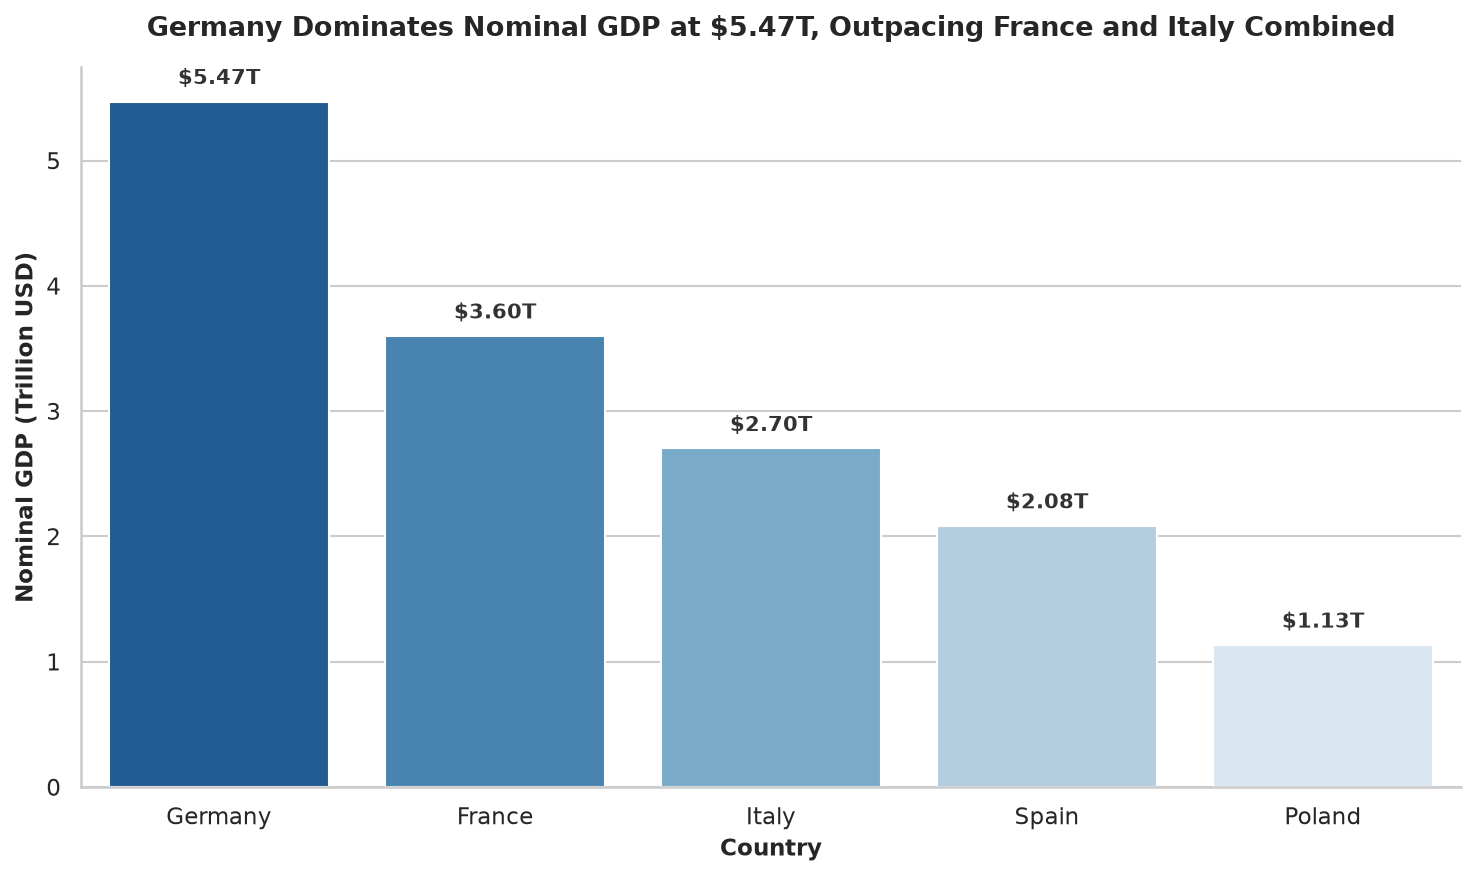

In [3]:
# Plot 1: Nominal GDP Comparison across the 5 Nations
fig, ax = plt.subplots(figsize=(10, 6))

gdp_sorted = df.sort_values(by='Nominal_GDP_Trillion_USD', ascending=False).reset_index(drop=True)
bars = sns.barplot(x='Country', y='Nominal_GDP_Trillion_USD', data=gdp_sorted, palette='Blues_r', ax=ax)

ax.set_title("Germany Dominates Nominal GDP at $5.47T, Outpacing France and Italy Combined", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Country", fontsize=11, fontweight='semibold')
ax.set_ylabel("Nominal GDP (Trillion USD)", fontsize=11, fontweight='semibold')

for bar in bars.patches:
    height = bar.get_height()
    ax.annotate(f"${height:.2f}T",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='#333333')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

C:\Users\xavie\AppData\Local\Temp\ipykernel_23488\3034994432.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars2 = sns.barplot(x='Country', y='Growth_Percentage', data=growth_sorted, palette='magma', ax=ax)


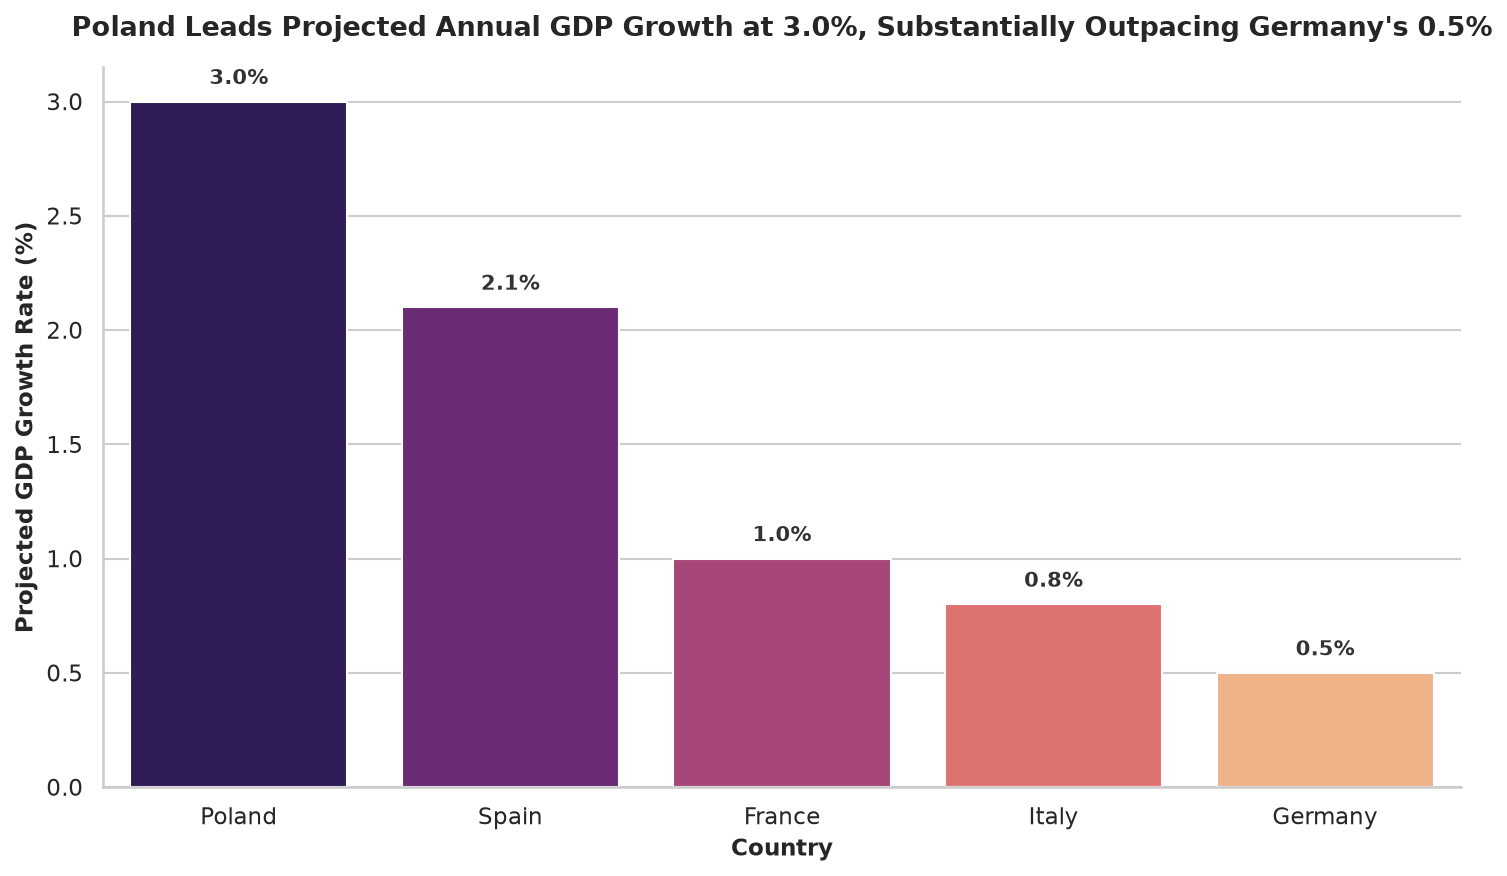

In [4]:
# Plot 2: Projected Economic Growth Percentage Ranking
fig, ax = plt.subplots(figsize=(10, 6))

growth_sorted = df.sort_values(by='Growth_Percentage', ascending=False).reset_index(drop=True)
bars2 = sns.barplot(x='Country', y='Growth_Percentage', data=growth_sorted, palette='magma', ax=ax)

ax.set_title("Poland Leads Projected Annual GDP Growth at 3.0%, Substantially Outpacing Germany's 0.5%", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Country", fontsize=11, fontweight='semibold')
ax.set_ylabel("Projected GDP Growth Rate (%)", fontsize=11, fontweight='semibold')

for bar in bars2.patches:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='#333333')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()